<table style="border:0;width:100%;border-collapse:collapse"><tr style="border:0"><td style="border:0;width:105px;vertical-align:middle"><img src="../Imagenes/logo-final-ap.png" width="90"/></td><td style="border:0;vertical-align:middle"><span style="font-size:32px;font-weight:700;color:#bd232b">Aprendizaje Profundo</span></td></tr></table>

[https://github.com/AprendizajeProfundo](https://github.com/AprendizajeProfundo)

# <span style="color:#174ea6">Cuaderno 106 · Optimización multiobjetivo: Pareto y decisiones industriales</span>

**Sesión 3 · Segunda lección · 40 minutos en clase (ampliaciones para estudio autónomo)**

**Autores:** Alvaro Montenegro · Daniel Montenegro · Pilar Montenegro  
**Docente:** Alvaro Montenegro, [ammontenegrod@gmail.com](mailto:ammontenegrod@gmail.com),  
**Institución:** Universidad de los Andes - Ecopetrol  
**Edición docente:** 106 · Octubre de 2026  
**Licencia del contenido y código originales de esta edición:** MIT (véase sección final).

> **Pregunta rectora.** ¿Por qué la configuración que minimiza la energía puede ser una mala decisión para una red de transporte de hidrocarburos?

**Fuentes directas:** programa aprobado de la sesión 3, cuaderno `105_ar_Optimizacion_Bayesiana.ipynb`, documentación de Hydro-Lab S2.11 y la arquitectura G2.4. Los experimentos son **sintéticos**, no mediciones industriales ni resultados ejecutados en Hydro-Lab.

# <span style="color:#174ea6">Contenido y ruta de clase</span>

**0–5 min:** recuperar el problema de BO y los parámetros de control. **5–15 min:** cuatro objetivos, restricciones y dominancia. **15–25 min:** obtener y visualizar un conjunto no dominado. **25–35 min:** incorporar preferencias y restricciones para decidir. **35–40 min:** defender una decisión ejecutiva. La sección de ampliación puede realizarse después de clase.

1. De un óptimo escalar a una decisión con compromisos. 2. Formulación matemática. 3. Dominancia y frente de Pareto. 4. Experimento reproducible. 5. Preferencias y decisión ejecutiva. 6. Integración con Hydro-Lab. 7. Actividades, referencias y licencia.

# <span style="color:#174ea6">1. Del óptimo de un indicador a una decisión industrial</span>

Una configuración que reduce el consumo eléctrico puede producir presión insuficiente, deteriorar la continuidad del servicio o aumentar las maniobras. No hay motivo para esperar que **una misma política optimice simultáneamente todos los indicadores**.

<img src="../Imagenes/arquitectura_laboratorio_G2.4.png" width="1050"/>

**Caso de estudio:** una red sintética de hidrocarburos con bombas, tuberías, terminales y robot de inspección. El problema es seleccionar parámetros de control, no sustituir el sistema de seguridad. El modelo que sigue es didáctico: los indicadores y sus unidades no deben confundirse con datos de una instalación real.

## <span style="color:#bd232b">1.1 De la sesión anterior a esta</span>

En el cuaderno 105 estudiamos cómo seleccionar el próximo punto de evaluación cuando cada simulación cuesta recursos. Allí se utilizó una función escalar $f(x)$. Ahora cada evaluación produce un **vector**:

$$\mathbf f(x)=\big(f_E(x),f_D(x),f_W(x),f_I(x)\big),$$

donde $f_E$ representa energía, $f_D$ déficit de servicio, $f_W$ desgaste y $f_I$ costo neto de inspección. **Todos se minimizan**; fijar una convención de signos evita errores de dominancia.

**Advertencia:** el beneficio de inspeccionar puede expresarse como reducción de pérdida esperada, pero no se obtiene gratis: hay tiempo, batería y costo de operación.

# <span style="color:#174ea6">2. Formulación matemática: objetivos, restricciones y factibilidad</span>

Sea $x\in\mathcal X$ el vector de parámetros del controlador. El problema multiobjetivo es

$$\min_{x\in\mathcal X}\;\mathbf f(x)=(f_1(x),\ldots,f_m(x))\quad\text{sujeto a}\quad g_j(x)\leq 0,\;j=1,\ldots,J.$$

El conjunto factible es $\mathcal F=\{x\in\mathcal X:g_j(x)\leq0\;\forall j\}$. Una solución con muy buen costo energético pero que viola restricciones de presión **no compite** con las configuraciones factibles: se descarta antes de construir el frente de Pareto.

En una aplicación industrial distinguiríamos:

- **Restricciones duras:** presión máxima, caudal mínimo exigido, límites de equipos, seguridad y batería.
- **Objetivos negociables:** consumo, maniobras, retrasos o costo de inspección, dentro de la región segura.

No reemplazaremos restricciones duras por penalizaciones arbitrarias salvo que el diseño del experimento lo justifique explícitamente.

## <span style="color:#bd232b">2.1 Dominancia y no dominancia</span>

Dados dos candidatos **factibles** $x,y$, decimos que $x$ domina a $y$, y escribimos $x\prec y$, si

$$f_i(x)\le f_i(y)\quad\forall i\in\{1,\ldots,m\},\qquad\exists j:\;f_j(x)<f_j(y).$$

El **conjunto no dominado** de un conjunto finito de candidatos $S\subset\mathcal F$ es

$$\operatorname{ND}(S)=\{x\in S:\nexists y\in S\text{ tal que }y\prec x\}.$$

El **frente de Pareto** es la imagen en el espacio de objetivos del conjunto Pareto-óptimo sobre toda la región factible. Con evaluaciones finitas solo obtenemos una **aproximación**; no debemos llamarla frente verdadero.

## <span style="color:#bd232b">2.2 Ejemplo de tres alternativas</span>

Considera dos indicadores a minimizar: energía y déficit de servicio. A = (5, 7), B = (7, 4), C = (8, 8). A domina C, mientras que A y B son no dominadas entre sí. La comparación entre A y B exige una preferencia adicional: ¿cuánta energía vale evitar una unidad de déficit?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ALTERNATIVAS = pd.DataFrame({"solucion": ["A", "B", "C"], "energia": [5., 7., 8.], "deficit": [7., 4., 8.]})

def domina(a, b, atol=1e-12):
    """Dominancia de Pareto para vectores de objetivos a minimizar."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    return bool(np.all(a <= b + atol) and np.any(a < b - atol))

def mascara_no_dominados(Y):
    Y = np.asarray(Y, dtype=float)
    if Y.ndim != 2 or not np.isfinite(Y).all():
        raise ValueError("Y debe ser una matriz finita (candidatos x objetivos)")
    n = len(Y)
    mask = np.ones(n, dtype=bool)
    for i in range(n):
        if any(domina(Y[j], Y[i]) for j in range(n) if j != i):
            mask[i] = False
    return mask

assert domina([5, 7], [8, 8])
assert not domina([5, 7], [7, 4])
assert mascara_no_dominados(ALTERNATIVAS[["energia", "deficit"]].to_numpy()).tolist() == [True, True, False]
print(ALTERNATIVAS.assign(no_dominada=mascara_no_dominados(ALTERNATIVAS[["energia", "deficit"]])))

  solucion  energia  deficit  no_dominada
0        A      5.0      7.0         True
1        B      7.0      4.0         True
2        C      8.0      8.0        False


# <span style="color:#174ea6">3. Un laboratorio sintético de control y operación</span>

## <span style="color:#bd232b">3.1 Parámetros, escenarios y objetivos</span>

Para que la lección sea reproducible sin ejecutar Hydro-Lab, definimos un **modelo sintético explícito**, sin pretensión de fidelidad hidráulica. Cada candidato es $x=(u,v,z)$:

- $u\in[0,1]$: intensidad normalizada de bombeo.
- $v\in[0,1]$: intensidad de respuesta o ajuste del controlador.
- $z\in[0,1]$: fracción normalizada de esfuerzo de inspección.

Las cuatro funciones producen **índices normalizados ilustrativos**, no kWh, barriles, horas ni fallas reales. Introducimos un escenario $s$ que modifica la demanda. Para construir el conjunto de candidatos, evaluamos una condición nominal $s=0$. Luego utilizamos escenarios **disjuntos** para examinar la robustez de la decisión.

**Regla de factibilidad didáctica:** déficit de servicio $\le 0.42$ y carga de inspección $z\le0.85$. En un modelo físico real, las restricciones provendrían del simulador y de criterios operacionales documentados.

In [2]:
SEMILLA = 106
rng = np.random.default_rng(SEMILLA)

def evaluar_sintetico(X, escenario=0.0):
    """Devuelve índices [energía, déficit, desgaste, costo neto de inspección], todos a minimizar."""
    X = np.atleast_2d(np.asarray(X, float))
    if X.shape[1] != 3 or np.any((X < 0) | (X > 1)):
        raise ValueError("X debe tener 3 parámetros en [0, 1]")
    u, v, z = X.T
    demanda = 0.56 + float(escenario)
    energia = 0.12 + 0.63*u**2 + 0.11*v**2 + 0.06*z
    deficit = np.maximum(0., demanda - 0.72*u - 0.19*v) + 0.035*(1-z)
    desgaste = 0.08 + 0.42*u**2 + 0.26*v**2 + 0.14*u*v - 0.06*z
    costo_inspeccion = 0.20 + 0.47*z**2 + 0.19*(1-z)**2 - 0.12*z*(0.5+u)
    return np.column_stack([energia, deficit, desgaste, costo_inspeccion])

n_candidatos = 320
X = rng.uniform(0, 1, size=(n_candidatos, 3))
Y = evaluar_sintetico(X, escenario=0.0)
factible = (Y[:,1] <= 0.42) & (X[:,2] <= 0.85)
nd_local = mascara_no_dominados(Y[factible])
indices_factibles = np.flatnonzero(factible)
indices_pareto = indices_factibles[nd_local]
print(f"Candidatos: {len(X)} | Factibles: {factible.sum()} | No dominados: {len(indices_pareto)}")
assert len(indices_pareto) > 1 and np.all(factible[indices_pareto])
assert not any(domina(Y[j],Y[i]) for i in indices_pareto for j in indices_pareto if j != i)

Candidatos: 320 | Factibles: 237 | No dominados: 169


## <span style="color:#bd232b">3.2 Visualización de la aproximación al frente</span>

Una proyección bidimensional puede ocultar relaciones de dominancia cuando hay cuatro objetivos. Por eso **calculamos la no dominancia en las cuatro dimensiones** y después representamos distintas proyecciones. Un punto aparentemente dominado en la figura puede ser no dominado en el espacio completo.

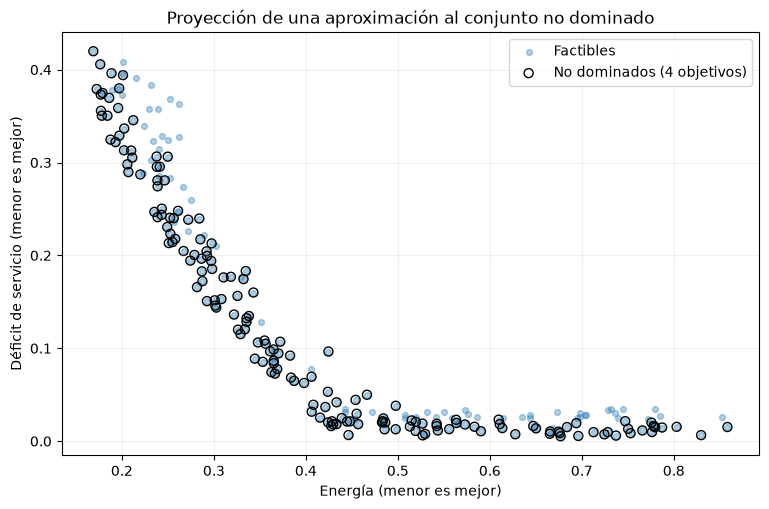

In [3]:
nombres = ["Energía", "Déficit de servicio", "Desgaste", "Costo neto inspección"]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(Y[factible,0], Y[factible,1], s=18, alpha=.35, label="Factibles")
ax.scatter(Y[indices_pareto,0], Y[indices_pareto,1], s=42, facecolors="none", edgecolors="black", linewidths=1.0, label="No dominados (4 objetivos)")
ax.set(xlabel=nombres[0]+" (menor es mejor)", ylabel=nombres[1]+" (menor es mejor)", title="Proyección de una aproximación al conjunto no dominado")
ax.legend(); ax.grid(alpha=.2); plt.show()

## <span style="color:#bd232b">3.3 Las cuatro dimensiones importan</span>

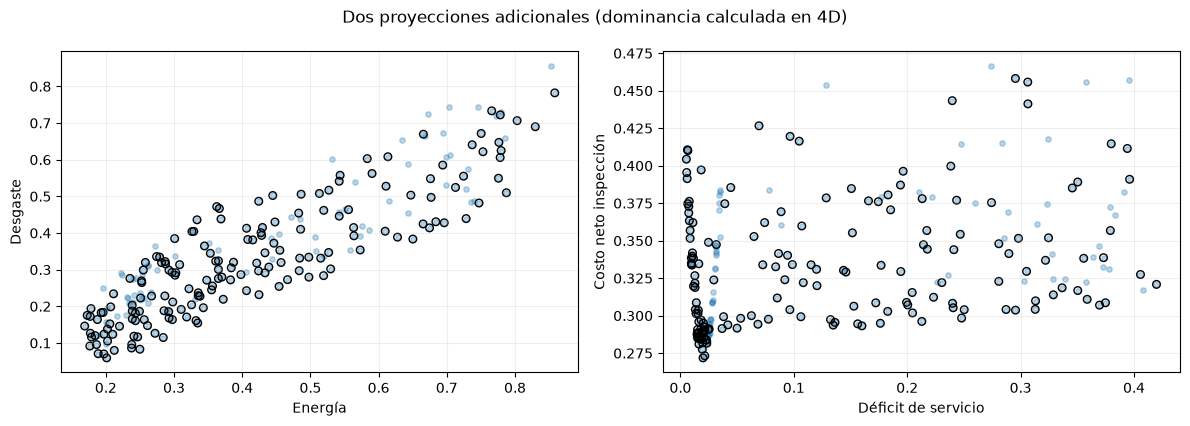

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12,4.3))
for ax, (i,j) in zip(axes, [(0,2),(1,3)]):
    ax.scatter(Y[factible,i],Y[factible,j],alpha=.3,s=15)
    ax.scatter(Y[indices_pareto,i],Y[indices_pareto,j],facecolors="none",edgecolors="black",s=30)
    ax.set(xlabel=nombres[i],ylabel=nombres[j]);ax.grid(alpha=.2)
fig.suptitle("Dos proyecciones adicionales (dominancia calculada en 4D)")
plt.tight_layout();plt.show()

# <span style="color:#174ea6">4. ¿Cómo pasar del conjunto no dominado a una decisión?</span>

## <span style="color:#bd232b">4.1 Normalización y preferencias explícitas</span>

La no dominancia **no ordena completamente** las alternativas. Una organización debe expresar prioridades. Una regla transparente es la suma ponderada de objetivos normalizados:

$$S_w(x)=\sum_{i=1}^{m}w_i\,\frac{f_i(x)-\ell_i}{u_i-\ell_i},\qquad w_i\ge0,\quad\sum_iw_i=1.$$

Los extremos $\ell_i,u_i$ deben fijarse con criterios documentados; para el ejercicio usamos el rango observado **entre candidatos factibles**. Esto no convierte pesos en tasas económicas de sustitución y puede alterar resultados al cambiar el conjunto de referencia.

**Limitación teórica:** la suma ponderada puede no recuperar puntos eficientes situados en regiones no convexas del frente, aun variando los pesos. Alternativas: restricciones $\varepsilon$, programación por metas o métodos específicos de optimización multiobjetivo.

In [5]:
Yf = Y[factible]
min_ref = Yf.min(axis=0)
span_ref = np.maximum(Yf.max(axis=0) - min_ref, 1e-12)
Ynorm = (Y - min_ref)/span_ref
preferencias = {
    "Continuidad del servicio": np.array([.15, .55, .20, .10]),
    "Eficiencia energética": np.array([.55, .20, .15, .10]),
    "Balance operacional": np.array([.25, .35, .25, .15]),
}
selecciones = {}
for nombre, pesos in preferencias.items():
    elegido = indices_pareto[np.argmin(Ynorm[indices_pareto] @ pesos)]
    selecciones[nombre] = elegido
    print(nombre, "| índice:", elegido, "| x:", X[elegido].round(3), "| f:", Y[elegido].round(3))
assert all(factible[i] for i in selecciones.values())

Continuidad del servicio | índice: 107 | x: [0.681 0.377 0.478] | f: [0.457 0.018 0.319 0.291]
Eficiencia energética | índice: 100 | x: [0.299 0.302 0.268] | f: [0.202 0.313 0.138 0.31 ]
Balance operacional | índice: 107 | x: [0.681 0.377 0.478] | f: [0.457 0.018 0.319 0.291]


## <span style="color:#bd232b">4.2 La decisión ejecutiva, con sus renuncias</span>

In [6]:
tabla = []
for perfil, idx in selecciones.items():
    fila = {"Preferencia": perfil, "ID": int(idx), "u":X[idx,0], "v":X[idx,1], "z":X[idx,2]}
    fila.update(dict(zip(nombres,Y[idx])))
    tabla.append(fila)
df_decision = pd.DataFrame(tabla).set_index("Preferencia")
print(df_decision.round(3).to_string())

                           ID      u      v      z  Energía  Déficit de servicio  Desgaste  Costo neto inspección
Preferencia                                                                                                      
Continuidad del servicio  107  0.681  0.377  0.478    0.457                0.018     0.319                  0.291
Eficiencia energética     100  0.299  0.302  0.268    0.202                0.313     0.138                  0.310
Balance operacional       107  0.681  0.377  0.478    0.457                0.018     0.319                  0.291


**Lectura obligatoria.** Ningún candidato de esta tabla es “el mejor” sin especificar preferencias. La decisión debe documentar: factibilidad, criterios, pesos, escala de indicadores, escenario de selección, sensibilidad y qué objetivo se sacrifica. Si una preferencia modifica los límites de seguridad, **no** debe implementarse: las restricciones son previas a la negociación.

## <span style="color:#bd232b">4.3 Sensibilidad a los pesos (ampliación)</span>

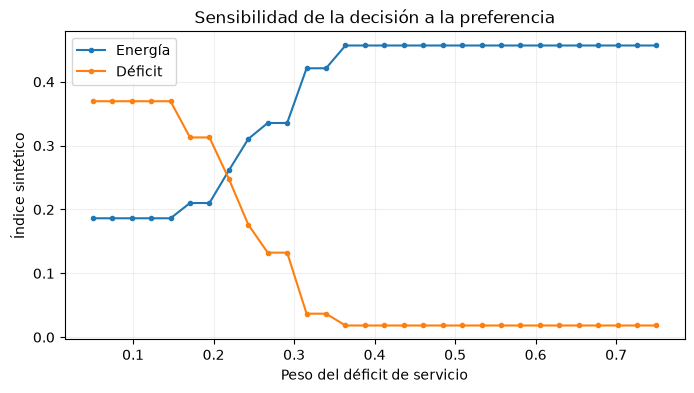

In [7]:
w_servicio = np.linspace(.05,.75,30)
ids=[]
for w in w_servicio:
    pesos = np.array([.45*(1-w), w, .40*(1-w), .15*(1-w)])
    ids.append(indices_pareto[np.argmin(Ynorm[indices_pareto]@pesos)])
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(w_servicio,[Y[i,0] for i in ids],marker=".",label="Energía")
ax.plot(w_servicio,[Y[i,1] for i in ids],marker=".",label="Déficit")
ax.set(xlabel="Peso del déficit de servicio",ylabel="Índice sintético",title="Sensibilidad de la decisión a la preferencia")
ax.legend();ax.grid(alpha=.2);plt.show()

# <span style="color:#174ea6">5. Evaluación independiente y robustez de la selección</span>

**Separación experimental.** Elegimos las configuraciones usando el escenario nominal. Después evaluamos las configuraciones ya seleccionadas en escenarios de demanda no utilizados para elegirlas. No volvemos a optimizar pesos ni parámetros con esos resultados: hacerlo contaminaría la evaluación de generalización.

Esta prueba no equivale a una auditoría de seguridad hidráulica; es una comprobación metodológica de robustez ante un cambio sintético de escenario.

In [8]:
escenarios_prueba = np.array([-0.08, 0.06, 0.13])
filas=[]
for perfil,idx in selecciones.items():
    for esc in escenarios_prueba:
        y = evaluar_sintetico(X[idx],escenario=esc)[0]
        filas.append({"perfil":perfil,"escenario":esc,"energia":y[0],"deficit":y[1],"desgaste":y[2],"inspeccion":y[3],"cumple_deficit":bool(y[1]<=.42)})
df_prueba=pd.DataFrame(filas)
print(df_prueba.round(3).to_string(index=False))
print("\nCumplimiento por preferencia (escenarios de prueba):")
print(df_prueba.groupby("perfil")["cumple_deficit"].mean().to_string())

                  perfil  escenario  energia  deficit  desgaste  inspeccion  cumple_deficit
Continuidad del servicio      -0.08    0.457    0.018     0.319       0.291            True
Continuidad del servicio       0.06    0.457    0.076     0.319       0.291            True
Continuidad del servicio       0.13    0.457    0.146     0.319       0.291            True
   Eficiencia energética      -0.08    0.202    0.233     0.138       0.310            True
   Eficiencia energética       0.06    0.202    0.373     0.138       0.310            True
   Eficiencia energética       0.13    0.202    0.443     0.138       0.310           False
     Balance operacional      -0.08    0.457    0.018     0.319       0.291            True
     Balance operacional       0.06    0.457    0.076     0.319       0.291            True
     Balance operacional       0.13    0.457    0.146     0.319       0.291            True

Cumplimiento por preferencia (escenarios de prueba):
perfil
Balance operacional

# <span style="color:#174ea6">6. Integración con Hydro-Lab S2.11</span>

## <span style="color:#bd232b">6.1 Contrato de evaluación industrial</span>

En Hydro-Lab cada candidato sería un **controlador parametrizado** o una política fija que se ejecuta sobre una batería de escenarios predefinidos. El simulador produce trayectorias, métricas y eventos de seguridad. Una integración real requiere identificar, con el código del repositorio, las métricas disponibles y su sentido operacional antes de definir los objetivos.

**Protocolo recomendado:**

1. Definir parámetros ajustables del controlador y sus límites; fijar una política de referencia.
2. Separar escenarios de **selección** y **evaluación final**, y fijar semillas.
3. Ejecutar todos los candidatos bajo el mismo presupuesto y condiciones comparables.
4. Aplicar **filtros de factibilidad y seguridad** antes de comparar objetivos.
5. Agregar objetivos por escenario de forma explícita (media, peor caso o cuantiles) y reportar variabilidad.
6. Calcular no dominancia con todas las dimensiones; no confundir la proyección 2D con el frente completo.
7. Presentar dos o tres candidatos y sus compromisos; elegir según preferencias documentadas.
8. Validar la decisión elegida en escenarios independientes, informando terminaciones anticipadas.

**No se han ejecutado estos experimentos sobre Hydro-Lab en este cuaderno.** El modelo del laboratorio es ilustrativo y no reemplaza la simulación física.

## <span style="color:#bd232b">6.2 Conexión con optimización bayesiana</span>

Cuando evaluar candidatos en Hydro-Lab resulta costoso, podemos combinar el cuaderno 105 con este enfoque. Una estrategia simple es escalarizar temporalmente $\mathbf f(x)$ con pesos explícitos y aplicar BO; otra es utilizar optimización bayesiana multiobjetivo para buscar mejoras del conjunto no dominado (por ejemplo, métodos basados en *hypervolume improvement*).

**Precaución:** variar pesos y llamar BO repetidamente no garantiza recuperar todo el frente, y comparar métodos exige presupuestos idénticos y métricas comunes. Aquí **no implementamos** un algoritmo multiobjetivo bayesiano; distinguimos deliberadamente entre el procedimiento implementado y las posibles extensiones.

# <span style="color:#174ea6">7. Actividades y evaluación</span>

**Actividad A (fundamentos).** Demuestra formalmente que la relación de dominancia estricta definida en este cuaderno es irreflexiva y transitiva. Construye dos alternativas no comparables.

**Actividad B (código).** Añade un quinto objetivo a la matriz de resultados, calcula el nuevo conjunto no dominado y explica por qué puede aumentar su tamaño.

**Actividad C (preferencias).** Modifica los pesos del decisor y documenta cómo cambia la selección. ¿Qué diferencias observas entre optimizar energía y priorizar el servicio?

**Actividad D (robustez).** En los escenarios de prueba, identifica configuraciones que pierden factibilidad. Explica por qué la no dominancia nominal no es garantía de seguridad.

**Decisión ejecutiva (entregable).** Redacta un párrafo que incluya: configuración elegida, criterios de factibilidad, objetivos sacrificados, sensibilidad a preferencias, incertidumbre y validación pendiente.

**Pregunta de contraste:** ¿por qué un óptimo de un indicador puede ser una mala decisión industrial?

# <span style="color:#174ea6">8. Referencias y lecturas</span>

1. Miettinen, K. (1999). *Nonlinear Multiobjective Optimization*. Springer.
2. Deb, K. (2001). *Multi-Objective Optimization Using Evolutionary Algorithms*. Wiley.
3. Ehrgott, M. (2005). *Multicriteria Optimization* (2.ª ed.). Springer.
4. Knowles, J. (2006). ParEGO: a hybrid algorithm with on-line landscape approximation for expensive multiobjective optimization problems. *IEEE Transactions on Evolutionary Computation*, 10(1), 50–66.
5. Daulton, S., Balandat, M. y Bakshy, E. (2020). Differentiable Expected Hypervolume Improvement for Parallel Multi-Objective Bayesian Optimization. *NeurIPS*.
6. **Aprendizaje Profundo**. Cuaderno 105, *Optimización bayesiana: aprender dónde evaluar* (edición docente, 2026).
7. Documentación del proyecto Hydro-Lab S2.11, manual y guía de estudiantes (material del curso).

Las referencias externas sustentan las definiciones y métodos generales; el modelo sintético, las figuras computacionales y los resultados de este cuaderno son construcciones didácticas.

## <span style="color:#bd232b">Créditos, figuras y licencia</span>

**Autores:** Alvaro Montenegro, Daniel Montenegro y Pilar Montenegro.  
**Docente:** Alvaro Montenegro.  
**Institución:** Universidad de los Andes - Ecopetrol.  
**Producción académica:** Aprendizaje Profundo.

**Licencia:** MIT para el código y los textos originales de esta edición, bajo titularidad de sus respectivos autores. Los archivos, imágenes, extractos o materiales de terceros conservan sus propias condiciones y atribuciones. El uso de los nombres institucionales no implica que esas instituciones hayan cedido derechos o aprobado licencias sobre materiales ajenos. La licencia MIT completa debe acompañar la distribución de la colección en su archivo `LICENSE`.